# BBM418 / AIN433 — Fundamentals of Computer Vision  
## Programming Assignment 2: Object Localization and Single-Object Tracking

### Student Notebook

This notebook is the starter template for the assignment. This is a draft.
You can follow the given structure or you can implement your version.
Feel free to change given code templates.

The assignment has five main parts:

1. Dataset loading and visualization  
2. Search-region sample generation  
3. CNN-based bounding-box regression model  
4. Single-object tracking on validation and test sequences  
5. Validation evaluation and analysis  

Keep your implementation clean, reproducible, and easy to follow.

### Student Info

#### Name: Mustafa Emir Tezcan

#### ID: 2230356092

#### The full submission ZIP file can be accessed from the following Google Drive link: https://drive.google.com/file/d/1O7QZFf4Adny6GeKEYU6TGrLZfrBrQ1cb/view?usp=sharing

## Assignment Setting

You will work with the given single-object tracking dataset.

### Training and Validation Sequences

These contain full ground-truth annotations:

```text
SequenceName/
  img/
    0001.jpg
    0002.jpg
    ...
  groundtruth_rect.txt
```

### Test Sequences

These contain only the first-frame initialization box:

```text
SequenceName/
  img/
    0001.jpg
    0002.jpg
    ...
  init_rect.txt
```

## Important Rule

For validation and test tracking, you may use only the first-frame bounding box to initialize the tracker.

After the first frame, all bounding boxes must be predicted by your tracker.

For validation sequences, later ground-truth boxes may be used **only after tracking** to compute evaluation metrics.

For test sequences, ground truth is hidden and must not be used.

## Expected Output

Your notebook should generate prediction CSV files for the test sequences.

Each file must be saved as:

```text
outputs/test/<sequence_name>_predictions.csv
```

The required CSV format is:

```text
frame,x,y,w,h
1,198,214,34,81
2,197.2,214.1,34.5,80.7
3,195.4,213.9,34.8,81.2
```

Coordinates must be full-frame pixel coordinates in `(x, y, width, height)` format. Do **not** save normalized crop coordinates.

# 0. Imports and Configuration

Run this section first. You may add extra imports if needed.

Make sure the paths below match your local folder structure.

In [1]:
import os
import csv
import math
import random
from copy import deepcopy
from pathlib import Path
from dataclasses import dataclass
from typing import Dict, List, Tuple, Optional

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms

In Google Colab environment, to download the dataset and extract it to the working directory you may use the following cell.

In [2]:
# 1. Configuration
FILE_ID = '1q8AAAQ64QwA16gU5jEKDvPure7CVajUt'
ZIP_NAME = 'dataset.zip'

# 2. Download the file
!gdown --id {FILE_ID} -O {ZIP_NAME}

# 3. Extract directly to /content
# This will result in: /content/data/sequences/ and /content/data/splits/
!unzip -q {ZIP_NAME} -d /content/

# 4. Cleanup the zip file
!rm {ZIP_NAME}

# 5. Verify the structure
print("Files in /content/data:", os.listdir("/content/data"))

/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1q8AAAQ64QwA16gU5jEKDvPure7CVajUt
From (redirected): https://drive.google.com/uc?id=1q8AAAQ64QwA16gU5jEKDvPure7CVajUt&confirm=t&uuid=23fa9ac4-e330-4faf-8658-2f133a28fa72
To: /content/dataset.zip
100% 1.64G/1.64G [00:15<00:00, 103MB/s]
Files in /content/data: ['splits', 'sequences']


## Reproducibility

Set random seeds so your results are more reproducible.
Include your seeds if you introduce additional randomness.

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

## Paths and Hyperparameters

Update `DATA_ROOT` if your dataset is located somewhere else.

The suggested hyperparameters are only starting points. You may change them, but report your final choices in the discussion section.

In [4]:
DATA_ROOT = Path("data/sequences")
SPLIT_ROOT = Path("data/splits")
OUTPUT_ROOT = Path("outputs")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_ROOT = Path("checkpoint")


DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = 224
SEARCH_SCALE = 2.5
BATCH_SIZE = 32
NUM_EPOCHS = 10
LEARNING_RATE = 1e-4
NUM_WORKERS = 0
TRAIN_AGAIN = False

print("Device:", DEVICE)
print("DATA_ROOT:", DATA_ROOT)

Device: cuda
DATA_ROOT: data/sequences


# PART 1 — Dataset Loading and Visualization

In this part, you will implement utilities for loading the dataset and visualizing bounding boxes.

You need separate loading functions for:

- training/validation sequences with `groundtruth_rect.txt`,
- test sequences with `init_rect.txt`.

This distinction is important because test sequences do not contain full ground truth.

## 1.1 Bounding-Box File Reader

The annotation files contain bounding boxes in the format:

```text
x,y,width,height
```

Some files may use commas, spaces, or tabs as separators. Your parser should handle these cases.

In [5]:
def read_bbox_file(path: Path) -> np.ndarray:
    """
    Read a bounding-box file.

    The file may contain one line or multiple lines.
    Each line has:
        x, y, width, height

    The parser should handle comma-separated, tab-separated,
    and whitespace-separated values.

    Returns:
        bboxes: numpy array of shape (N, 4)
    """
    rows = []
    with open(path, "r") as f:
        for line in f:
            if line.strip():
                rows.append([float(val) for val in line.replace(",", " ").split()])

    return np.array(rows, dtype=np.float32)

## 1.2 Frame Path Reader

This function should read all frame paths from the `img/` folder and sort them in frame order.

In [6]:
def get_frame_paths(sequence_path: Path) -> List[Path]:
    """
    Return sorted frame paths from sequence_path/img/.

    Returns:
        frame_paths: sorted list of image paths
    """
    img_dir = Path(sequence_path) / "img"

    image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}
    frame_paths = [
        path
        for path in img_dir.iterdir()
        if path.is_file() and path.suffix.lower() in image_extensions
    ]
    return sorted(
        frame_paths,
        key=lambda p: (0, int(p.stem), p.suffix.lower()) if p.stem.isdigit() else (1, p.name.lower())
    )

## 1.3 Load Training / Validation Sequences

Training and validation sequences contain full ground truth.

Your loader must check that:

```text
number of frames == number of ground-truth boxes
```

If there is a mismatch, raise an error. Do not silently truncate frames or annotations.

In [7]:
def load_sequence_with_gt(sequence_path: Path) -> Tuple[List[Path], np.ndarray]:
    """
    Load a training or validation sequence.

    Expected files:
        img/
        groundtruth_rect.txt

    Returns:
        frame_paths: sorted list of image paths
        bboxes: numpy array of shape (N, 4)

    Required check:
        len(frame_paths) must equal len(bboxes).
    """
    sequence_path = Path(sequence_path)
    gt_path = sequence_path / "groundtruth_rect.txt"
    if not gt_path.is_file():
        raise FileNotFoundError(f"Ground-truth file not found: {gt_path}")

    frame_paths = get_frame_paths(sequence_path)
    bboxes = read_bbox_file(gt_path)

    if len(frame_paths) != len(bboxes):
        raise ValueError(
            f"Frame/annotation mismatch in {sequence_path.name}: "
            f"{len(frame_paths)} frames but {len(bboxes)} boxes"
        )

    return frame_paths, bboxes

## 1.4 Load Test Sequences

Test sequences contain only `init_rect.txt`.

This file contains one bounding box: the first-frame initialization box.

Your test loader should not expect `groundtruth_rect.txt`.

In [8]:
def load_test_sequence(sequence_path: Path) -> Tuple[List[Path], np.ndarray]:
    """
    Load a hidden test sequence.

    Expected files:
        img/
        init_rect.txt

    Returns:
        frame_paths: sorted list of image paths
        initial_bbox: numpy array of shape (4,)
    """
    sequence_path = Path(sequence_path)
    init_path = sequence_path / "init_rect.txt"
    if not init_path.is_file():
        raise FileNotFoundError(f"Initialization file not found: {init_path}")

    frame_paths = get_frame_paths(sequence_path)
    init_bboxes = read_bbox_file(init_path)
    if len(init_bboxes) != 1:
        raise ValueError(f"Expected one initialization bbox in {init_path}, got {len(init_bboxes)}")

    return frame_paths, init_bboxes[0].astype(np.float32)

## 1.5 Image Reading and Drawing Utilities

Implement helper functions for reading RGB images and drawing bounding boxes.

These functions will be used throughout the notebook.

In [9]:
def read_image_rgb(path: Path) -> np.ndarray:
    """
    Read an image using OpenCV and convert it from BGR to RGB.
    """
    image_bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image_bgr is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    return cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)


def draw_bbox(
    image: np.ndarray,
    bbox: np.ndarray,
    color: Tuple[int, int, int] = (0, 255, 0),
    thickness: int = 2,
    label: Optional[str] = None,
) -> np.ndarray:
    """
    Draw a bounding box on an RGB image.

    Args:
        image: input RGB image
        bbox: bounding box in (x, y, w, h) format
        color: RGB color
        thickness: line thickness
        label: optional label text

    Returns:
        image_with_box
    """
    output = image.copy()
    x, y, w, h = np.asarray(bbox, dtype=np.float32)
    x1, y1 = int(round(x)), int(round(y))
    x2, y2 = int(round(x + w)), int(round(y + h))

    height, width = output.shape[:2]
    x1 = max(0, min(width - 1, x1))
    y1 = max(0, min(height - 1, y1))
    x2 = max(0, min(width - 1, x2))
    y2 = max(0, min(height - 1, y2))

    cv2.rectangle(output, (x1, y1), (x2, y2), color, thickness)

    if label:
        font = cv2.FONT_HERSHEY_SIMPLEX
        font_scale = 0.5
        text_thickness = 1
        (text_w, text_h), baseline = cv2.getTextSize(label, font, font_scale, text_thickness)
        label_y1 = max(0, y1 - text_h - baseline - 4)
        label_y2 = min(height - 1, label_y1 + text_h + baseline + 4)
        label_x2 = min(width - 1, x1 + text_w + 6)
        cv2.rectangle(output, (x1, label_y1), (label_x2, label_y2), color, -1)
        cv2.putText(
            output,
            label,
            (x1 + 3, label_y2 - baseline - 2),
            font,
            font_scale,
            (0, 0, 0),
            text_thickness,
            cv2.LINE_AA,
        )

    return output


def show_image(image: np.ndarray, title: str = "", figsize: Tuple[int, int] = (6, 4)):
    """Display an RGB image using matplotlib."""
    plt.figure(figsize=figsize)
    plt.imshow(image)
    plt.axis("off")
    plt.title(title)
    plt.show()

## 1.6 Sequence Listing

This helper is useful for checking which sequences exist under `DATA_ROOT`.

In [10]:
def list_sequences(data_root: Path) -> List[str]:
    """
    List valid sequence folders inside data_root.
    """
    data_root = Path(data_root)
    if not data_root.is_dir():
        raise FileNotFoundError(f"Data root not found: {data_root}")

    sequence_names = []
    for path in data_root.iterdir():
        if not path.is_dir():
            continue
        has_images = (path / "img").is_dir()
        has_annotation = (path / "groundtruth_rect.txt").is_file() or (path / "init_rect.txt").is_file()
        if has_images and has_annotation:
            sequence_names.append(path.name)

    return sorted(sequence_names)

## 1.7 Visualization Task

Visualize at least five frames from at least two training/validation sequences.

For each visualized frame, draw the ground-truth bounding box.

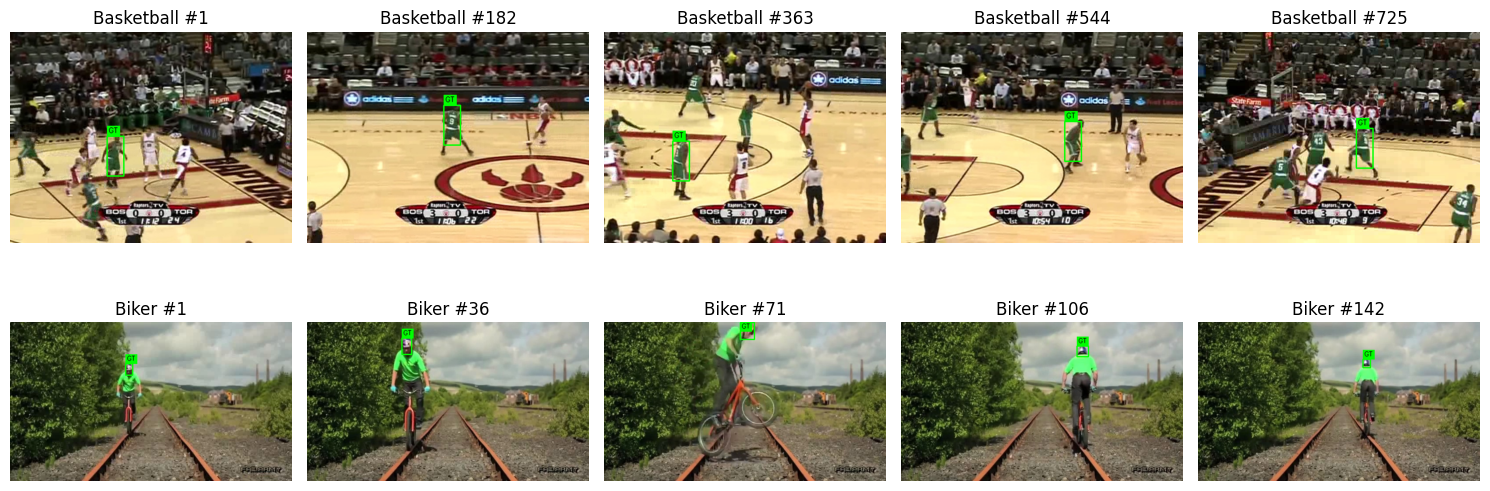

In [11]:
gt_sequence_names = [
    name
    for name in list_sequences(DATA_ROOT)
    if (DATA_ROOT / name / "groundtruth_rect.txt").is_file()
]

sample_sequences = gt_sequence_names[:2]
num_frames_to_show = 5

if len(sample_sequences) < 2:
    print("At least two full-GT sequences are required for this visualization.")
else:
    fig, axes = plt.subplots(
        len(sample_sequences),
        num_frames_to_show,
        figsize=(3 * num_frames_to_show, 3 * len(sample_sequences)),
        squeeze=False,
    )

    for row, sequence_name in enumerate(sample_sequences):
        frame_paths, bboxes = load_sequence_with_gt(DATA_ROOT / sequence_name)
        frame_indices = np.linspace(0, len(frame_paths) - 1, num_frames_to_show, dtype=int)

        for col, frame_idx in enumerate(frame_indices):
            image = read_image_rgb(frame_paths[frame_idx])
            image = draw_bbox(image, bboxes[frame_idx], color=(0, 255, 0), label="GT")
            axes[row, col].imshow(image)
            axes[row, col].axis("off")
            axes[row, col].set_title(f"{sequence_name} #{frame_idx + 1}")

    plt.tight_layout()
    fig.savefig(OUTPUT_ROOT / "sample_gt_visualizations.png", dpi=150, bbox_inches="tight")
    plt.show()

# Split Handling

The assignment uses fixed train/validation/test splits.

Use only the provided split files:

```text
splits/train.txt
splits/val.txt
splits/test.txt
```

Each file contains one sequence name per line.

## Split File Loading

Implement the functions below to read split files and verify that the sequence folders match the expected format.

In [12]:
def read_split_file(split_path: Path) -> List[str]:
    """Read sequence names from a split file."""
    split_path = Path(split_path)

    with split_path.open("r", encoding="utf-8") as f:
        return [
            line.strip()
            for line in f
            if line.strip() and not line.strip().startswith("#")
        ]


def load_splits(split_root: Path) -> Tuple[List[str], List[str], List[str]]:
    """Load train, validation, and test split files."""
    split_root = Path(split_root)
    train_sequences = read_split_file(split_root / "train.txt")
    val_sequences = read_split_file(split_root / "val.txt")
    test_sequences = read_split_file(split_root / "test.txt")
    return train_sequences, val_sequences, test_sequences


def verify_split_files(
    data_root: Path,
    train_sequences: List[str],
    val_sequences: List[str],
    test_sequences: List[str],
):
    """
    Verify that train/val sequences have groundtruth_rect.txt
    and test sequences have init_rect.txt.
    """
    data_root = Path(data_root)
    available = set(list_sequences(data_root))
    all_split_names = train_sequences + val_sequences + test_sequences
    missing = sorted(set(all_split_names) - available)
    if missing:
        raise FileNotFoundError(f"Sequences listed in splits but missing from data root: {missing}")

    split_sets = {
        "train": set(train_sequences),
        "val": set(val_sequences),
        "test": set(test_sequences),
    }
    overlaps = {
        ("train", "val"): split_sets["train"] & split_sets["val"],
        ("train", "test"): split_sets["train"] & split_sets["test"],
        ("val", "test"): split_sets["val"] & split_sets["test"],
    }
    bad_overlaps = {pair: sorted(names) for pair, names in overlaps.items() if names}
    if bad_overlaps:
        raise ValueError(f"Split files contain overlapping sequences: {bad_overlaps}")

    for split_name, sequence_names in [("train", train_sequences), ("val", val_sequences)]:
        for sequence_name in sequence_names:
            sequence_path = data_root / sequence_name
            if not (sequence_path / "groundtruth_rect.txt").is_file():
                raise FileNotFoundError(
                    f"{split_name} sequence {sequence_name} is missing groundtruth_rect.txt"
                )
            load_sequence_with_gt(sequence_path)

    for sequence_name in test_sequences:
        sequence_path = data_root / sequence_name
        if not (sequence_path / "init_rect.txt").is_file():
            raise FileNotFoundError(f"test sequence {sequence_name} is missing init_rect.txt")
        load_test_sequence(sequence_path)

    print("Split verification passed.")
    return True

## Load Splits

Run this cell after implementing the split-loading functions.

In [13]:
train_sequences, val_sequences, test_sequences = load_splits(SPLIT_ROOT)
verify_split_files(DATA_ROOT, train_sequences, val_sequences, test_sequences)

print(f"Train sequences: {len(train_sequences)}")
print(f"Validation sequences: {len(val_sequences)}")
print(f"Test sequences: {len(test_sequences)}")

Split verification passed.
Train sequences: 39
Validation sequences: 11
Test sequences: 7


# (Optional) Dataset Exploration

This section is not required for implementation, but it is helpful for understanding the dataset.

You may use these cells to inspect:

- sequence lengths,
- bounding-box size distribution,
- object trajectory,
- scale changes.

These visualizations can also help your discussions.

## (Optional) Dataset Summary

After loading the splits, summarize the number of frames and bounding-box sizes in the training and validation sets.

In [14]:
def summarize_sequences(data_root: Path, sequence_names: List[str], split_name: str) -> pd.DataFrame:
    """Summarize frame counts and target-box sizes for a dataset split."""
    rows = []
    for sequence_name in sequence_names:
        frame_paths, bboxes = load_sequence_with_gt(Path(data_root) / sequence_name)
        widths = bboxes[:, 2]
        heights = bboxes[:, 3]
        areas = widths * heights
        rows.append({
            "split": split_name,
            "sequence": sequence_name,
            "num_frames": len(frame_paths),
            "mean_width": float(np.mean(widths)),
            "mean_height": float(np.mean(heights)),
            "mean_area": float(np.mean(areas)),
            "min_area": float(np.min(areas)),
            "max_area": float(np.max(areas)),
        })
    return pd.DataFrame(rows)


if "train_sequences" not in globals() or "val_sequences" not in globals():
    train_sequences, val_sequences, test_sequences = load_splits(SPLIT_ROOT)

dataset_summary = pd.concat(
    [
        summarize_sequences(DATA_ROOT, train_sequences, "train"),
        summarize_sequences(DATA_ROOT, val_sequences, "val"),
    ],
    ignore_index=True,
)

dataset_summary.to_csv(OUTPUT_ROOT / "dataset_summary.csv", index=False)
split_summary = dataset_summary.groupby("split")[["num_frames", "mean_width", "mean_height", "mean_area"]].mean()
split_summary.to_csv(OUTPUT_ROOT / "dataset_split_summary.csv")

display(dataset_summary.head())
display(split_summary)

,split,sequence,num_frames,mean_width,mean_height,mean_area,min_area,max_area
0,train,Deer,71,85.253525,56.253521,4814.056152,3528.0,6860.0
1,train,Crossing,120,16.716667,42.158333,713.508362,403.0,1100.0
2,train,Boy,602,34.142857,43.259136,1493.325562,768.0,3283.0
3,train,Car1,1020,25.351961,21.015686,610.291199,255.0,3630.0
4,train,Walking2,500,22.945999,75.991997,1822.510010,686.0,4180.0


,num_frames,mean_width,mean_height,mean_area
split,,,,
train,681.717949,70.147052,100.808095,8725.763581
val,459.272727,45.781858,66.703711,3563.800848


## (Optional) Bounding-Box Distribution

Plot distributions of bounding-box width, height, area, or aspect ratio.

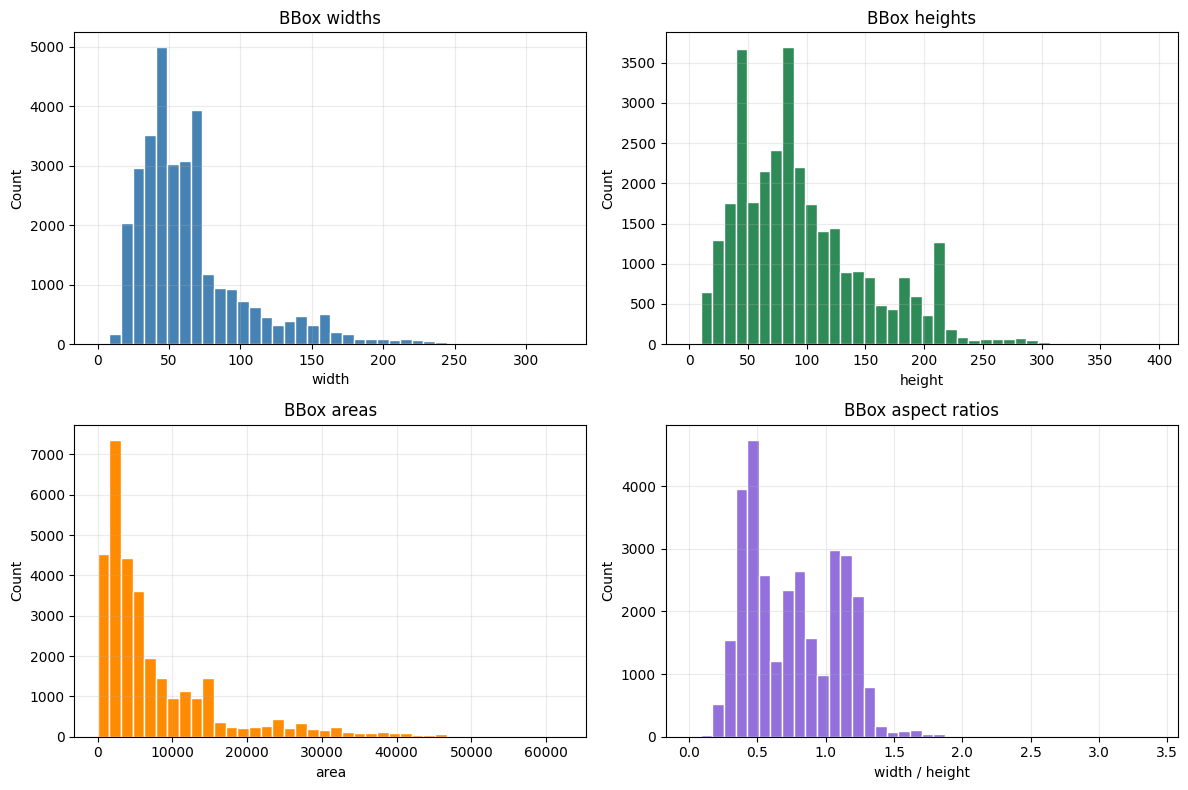

In [15]:
if "train_sequences" not in globals() or "val_sequences" not in globals():
    train_sequences, val_sequences, test_sequences = load_splits(SPLIT_ROOT)

all_boxes = []
for sequence_name in train_sequences + val_sequences:
    _, bboxes = load_sequence_with_gt(DATA_ROOT / sequence_name)
    all_boxes.append(bboxes)

all_boxes = np.concatenate(all_boxes, axis=0)
widths = all_boxes[:, 2]
heights = all_boxes[:, 3]
areas = widths * heights
aspect_ratios = widths / np.maximum(heights, 1e-6)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.ravel()

axes[0].hist(widths, bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("BBox widths")
axes[0].set_xlabel("width")

axes[1].hist(heights, bins=40, color="seagreen", edgecolor="white")
axes[1].set_title("BBox heights")
axes[1].set_xlabel("height")

axes[2].hist(areas, bins=40, color="darkorange", edgecolor="white")
axes[2].set_title("BBox areas")
axes[2].set_xlabel("area")

axes[3].hist(aspect_ratios, bins=40, color="mediumpurple", edgecolor="white")
axes[3].set_title("BBox aspect ratios")
axes[3].set_xlabel("width / height")

for ax in axes:
    ax.set_ylabel("Count")
    ax.grid(True, alpha=0.25)

plt.tight_layout()
fig.savefig(OUTPUT_ROOT / "bbox_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## (Optional) Target Motion Visualization

For one selected sequence, plot the target center coordinates over time.

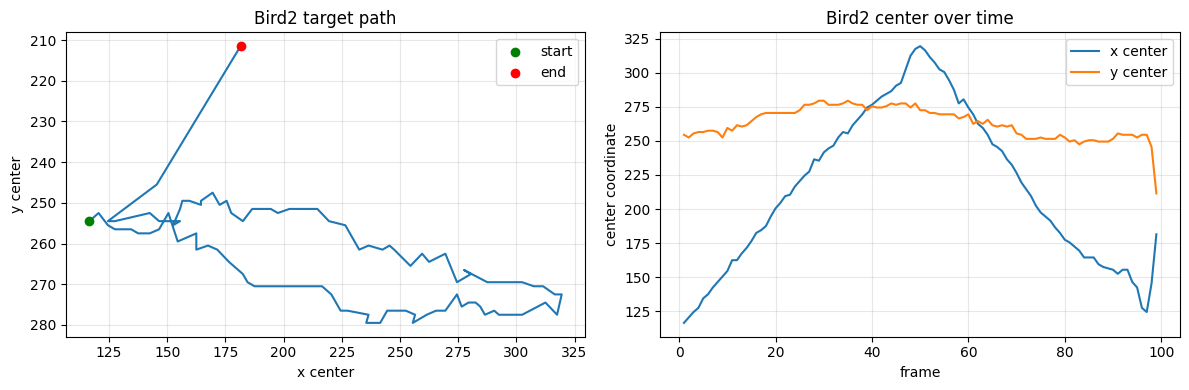

In [16]:
if "val_sequences" not in globals():
    train_sequences, val_sequences, test_sequences = load_splits(SPLIT_ROOT)

trajectory_sequence = val_sequences[0]
_, trajectory_bboxes = load_sequence_with_gt(DATA_ROOT / trajectory_sequence)
trajectory_centers = np.column_stack((
    trajectory_bboxes[:, 0] + trajectory_bboxes[:, 2] / 2.0,
    trajectory_bboxes[:, 1] + trajectory_bboxes[:, 3] / 2.0,
))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(trajectory_centers[:, 0], trajectory_centers[:, 1], linewidth=1.5)
axes[0].scatter(trajectory_centers[0, 0], trajectory_centers[0, 1], color="green", label="start", zorder=3)
axes[0].scatter(trajectory_centers[-1, 0], trajectory_centers[-1, 1], color="red", label="end", zorder=3)
axes[0].invert_yaxis()
axes[0].set_title(f"{trajectory_sequence} target path")
axes[0].set_xlabel("x center")
axes[0].set_ylabel("y center")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

frame_numbers = np.arange(1, len(trajectory_centers) + 1)
axes[1].plot(frame_numbers, trajectory_centers[:, 0], label="x center", linewidth=1.5)
axes[1].plot(frame_numbers, trajectory_centers[:, 1], label="y center", linewidth=1.5)
axes[1].set_title(f"{trajectory_sequence} center over time")
axes[1].set_xlabel("frame")
axes[1].set_ylabel("center coordinate")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
fig.savefig(OUTPUT_ROOT / "target_motion_visualization.png", dpi=150, bbox_inches="tight")
plt.show()

# PART 2 — Search-Region Sample Generation

In single-object tracking, the target is initialized in the first frame. For later frames, the tracker searches around the previous target location.

In this assignment, you will train a model that receives a local search crop and predicts the target box inside that crop.

For a pair of consecutive frames:

```text
Frame t-1 bbox -> used to define the search region in frame t
Frame t bbox   -> target label inside the search region
```

## 2.1 Crop Metadata

`CropInfo` stores the information needed to convert between:

- full-frame coordinates,
- crop-local normalized coordinates.

In [17]:
@dataclass
class CropInfo:
    """
    Metadata for mapping between crop coordinates and full-frame coordinates.

    x1, y1:
        Top-left location of the crop in the original image coordinate system.
        These may be negative if padding is used.

    crop_size:
        Side length of the square crop in original image pixels.

    output_size:
        Side length after resizing the crop for the CNN.
    """
    x1: float
    y1: float
    crop_size: float
    output_size: int

## 2.2 Bounding-Box Helper Functions

Implement simple helper functions for bounding-box center computation and clipping predictions to image boundaries.

In [18]:
def bbox_center(bbox: np.ndarray) -> Tuple[float, float]:
    """Compute the center of a bbox in (x, y, w, h) format."""
    x, y, w, h = np.asarray(bbox, dtype=np.float32)
    return float(x + w / 2.0), float(y + h / 2.0)


def clip_bbox_to_image(bbox: np.ndarray, image_shape: Tuple[int, int, int]) -> np.ndarray:
    """Clip a bbox to image boundaries and keep width/height positive."""
    x, y, w, h = np.asarray(bbox, dtype=np.float32)
    img_h, img_w = image_shape[:2]

    x1 = float(np.clip(x, 0, max(img_w - 1, 0)))
    y1 = float(np.clip(y, 0, max(img_h - 1, 0)))
    x2 = float(np.clip(x + max(w, 1.0), 0, img_w))
    y2 = float(np.clip(y + max(h, 1.0), 0, img_h))

    if x2 <= x1:
        x2 = min(float(img_w), x1 + 1.0)
        x1 = max(0.0, x2 - 1.0)
    if y2 <= y1:
        y2 = min(float(img_h), y1 + 1.0)
        y1 = max(0.0, y2 - 1.0)

    return np.array([x1, y1, x2 - x1, y2 - y1], dtype=np.float32)

## 2.3 Search-Region Crop

Use a square search region centered around the previous bounding box.

The recommended crop size is:

```text
crop_size = scale × max(previous_width, previous_height)
```

A reasonable default value is `scale = 2.5`.

If the crop goes outside the image, handle the boundary carefully. You may use padding or clipping, but your coordinate conversion must remain correct.

In [19]:
def crop_search_region(
    image: np.ndarray,
    previous_bbox: np.ndarray,
    scale: float = 2.5,
    output_size: int = IMAGE_SIZE,
    pad_value: Tuple[int, int, int] = (128, 128, 128),
) -> Tuple[np.ndarray, CropInfo]:
    """
    Crop a square search region around the previous bounding box.

    Returns:
        crop_resized: RGB crop resized to output_size x output_size
        crop_info: metadata for coordinate conversion
    """
    image_h, image_w = image.shape[:2]
    prev = np.asarray(previous_bbox, dtype=np.float32)
    center_x, center_y = bbox_center(prev)
    crop_size = max(1, int(round(scale * max(float(prev[2]), float(prev[3]), 1.0))))

    x1 = int(math.floor(center_x - crop_size / 2.0))
    y1 = int(math.floor(center_y - crop_size / 2.0))
    x2 = x1 + crop_size
    y2 = y1 + crop_size

    crop = np.full((crop_size, crop_size, 3), pad_value, dtype=image.dtype)

    src_x1 = max(0, x1)
    src_y1 = max(0, y1)
    src_x2 = min(image_w, x2)
    src_y2 = min(image_h, y2)

    if src_x2 > src_x1 and src_y2 > src_y1:
        dst_x1 = src_x1 - x1
        dst_y1 = src_y1 - y1
        dst_x2 = dst_x1 + (src_x2 - src_x1)
        dst_y2 = dst_y1 + (src_y2 - src_y1)
        crop[dst_y1:dst_y2, dst_x1:dst_x2] = image[src_y1:src_y2, src_x1:src_x2]

    crop_resized = cv2.resize(crop, (output_size, output_size), interpolation=cv2.INTER_LINEAR)
    crop_info = CropInfo(x1=float(x1), y1=float(y1), crop_size=float(crop_size), output_size=output_size)
    return crop_resized, crop_info

## 2.4 Coordinate Conversion

The model predicts boxes inside the crop, but the final tracking output must be in full-frame coordinates.

You need two conversions:

1. Full-frame bbox → crop-local normalized bbox  
2. Crop-local normalized bbox → full-frame bbox

In [20]:
def bbox_to_crop_coordinates(bbox: np.ndarray, crop_info: CropInfo) -> np.ndarray:
    """
    Convert a full-frame bbox into normalized crop coordinates.

    Returns:
        normalized_bbox: (x, y, w, h), usually in [0, 1]
    """
    x, y, w, h = np.asarray(bbox, dtype=np.float32)
    crop_x1 = crop_info.x1
    crop_y1 = crop_info.y1
    crop_x2 = crop_x1 + crop_info.crop_size
    crop_y2 = crop_y1 + crop_info.crop_size

    box_x1 = np.clip(x, crop_x1, crop_x2)
    box_y1 = np.clip(y, crop_y1, crop_y2)
    box_x2 = np.clip(x + w, crop_x1, crop_x2)
    box_y2 = np.clip(y + h, crop_y1, crop_y2)

    norm_x1 = (box_x1 - crop_x1) / crop_info.crop_size
    norm_y1 = (box_y1 - crop_y1) / crop_info.crop_size
    norm_x2 = (box_x2 - crop_x1) / crop_info.crop_size
    norm_y2 = (box_y2 - crop_y1) / crop_info.crop_size

    normalized = np.array(
        [
            norm_x1,
            norm_y1,
            max(norm_x2 - norm_x1, 1e-6),
            max(norm_y2 - norm_y1, 1e-6),
        ],
        dtype=np.float32,
    )
    return np.clip(normalized, 0.0, 1.0)


def crop_to_frame_coordinates(normalized_bbox: np.ndarray, crop_info: CropInfo) -> np.ndarray:
    """
    Convert a normalized crop-local bbox back to full-frame coordinates.
    """
    bbox = np.asarray(normalized_bbox, dtype=np.float32)
    bbox = np.clip(bbox, 0.0, 1.0)
    x = crop_info.x1 + float(bbox[0]) * crop_info.crop_size
    y = crop_info.y1 + float(bbox[1]) * crop_info.crop_size
    w = max(float(bbox[2]) * crop_info.crop_size, 1.0)
    h = max(float(bbox[3]) * crop_info.crop_size, 1.0)
    return np.array([x, y, w, h], dtype=np.float32)

## 2.5 Search-Region Visualization

Visualize several generated search-region samples.

For each sample, draw the current target box inside the search crop.

This is one of the most important sanity checks in the assignment.

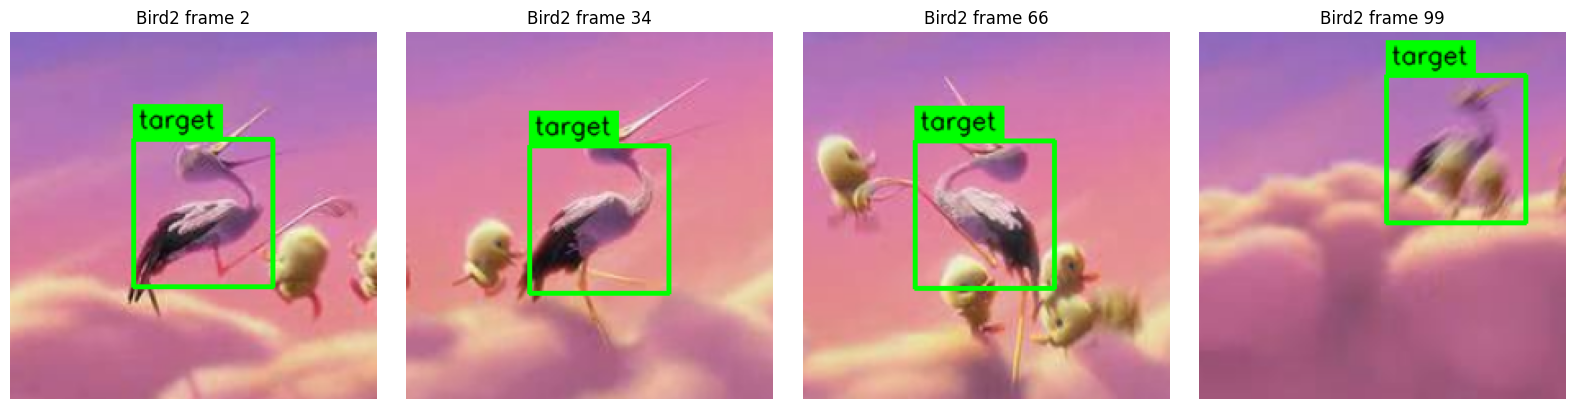

In [21]:
if "val_sequences" not in globals():
    train_sequences, val_sequences, test_sequences = load_splits(SPLIT_ROOT)

sample_sequence = val_sequences[0] if val_sequences else gt_sequence_names[0]
frame_paths, bboxes = load_sequence_with_gt(DATA_ROOT / sample_sequence)
sample_indices = np.linspace(1, len(frame_paths) - 1, 4, dtype=int)

fig, axes = plt.subplots(1, len(sample_indices), figsize=(4 * len(sample_indices), 4), squeeze=False)

for ax, frame_idx in zip(axes[0], sample_indices):
    image = read_image_rgb(frame_paths[frame_idx])
    crop_rgb, crop_info = crop_search_region(image, bboxes[frame_idx - 1], scale=SEARCH_SCALE)
    target_norm = bbox_to_crop_coordinates(bboxes[frame_idx], crop_info)
    target_pixels = target_norm * np.array([IMAGE_SIZE, IMAGE_SIZE, IMAGE_SIZE, IMAGE_SIZE], dtype=np.float32)
    crop_with_box = draw_bbox(crop_rgb, target_pixels, color=(0, 255, 0), label="target")
    ax.imshow(crop_with_box)
    ax.axis("off")
    ax.set_title(f"{sample_sequence} frame {frame_idx + 1}")

plt.tight_layout()
fig.savefig(OUTPUT_ROOT / "search_region_samples.png", dpi=150, bbox_inches="tight")
plt.show()


# PART 3 — CNN-Based Bounding-Box Regression Model

In this part, you will train a CNN to predict the target bounding box inside a search crop.

The model input is:

```text
224 × 224 RGB search crop
```

The model output is:

```text
x, y, width, height
```

The output must be crop-local and normalized to `[0, 1]`.

Do not train the model with full-frame coordinates.

## 3.1 Model Architecture Overview

Recommended architecture:

```text
Search Region Crop
        ↓
Preprocessing
        ↓
CNN Backbone
        ↓
Regression Head
        ↓
Normalized Bounding Box [x, y, w, h]
        ↓
Convert to full-frame coordinates during tracking
```

You may use an ImageNet-pretrained ResNet18 backbone. Replace its final classification layer with a regression layer that outputs four values.

## 3.2 PyTorch Dataset

Implement a PyTorch dataset that generates search-region samples from training sequences.

Each sample should contain:

```text
input: search crop from current frame
target: current target bbox in crop-local normalized coordinates
```

Use validation sequences similarly for crop-level validation.

In [22]:
class SearchRegionDataset(Dataset):
    """
    Dataset that generates search-region samples from full-GT sequences.

    Each sample:
        input: current frame search crop around previous GT bbox
        target: current GT bbox in normalized crop coordinates
    """

    def __init__(
        self,
        data_root: Path,
        sequence_names: List[str],
        image_size: int = IMAGE_SIZE,
        search_scale: float = SEARCH_SCALE,
        augment: bool = False,
    ):
        self.data_root = Path(data_root)
        self.sequence_names = list(sequence_names)
        self.image_size = image_size
        self.search_scale = search_scale
        self.augment = augment

        self.samples = []
        for sequence_name in self.sequence_names:
            frame_paths, bboxes = load_sequence_with_gt(self.data_root / sequence_name)
            for frame_idx in range(1, len(frame_paths)):
                self.samples.append({
                    "sequence_name": sequence_name,
                    "frame_index": frame_idx,
                    "frame_path": frame_paths[frame_idx],
                    "previous_bbox": bboxes[frame_idx - 1].astype(np.float32),
                    "current_bbox": bboxes[frame_idx].astype(np.float32),
                })

        self.transform = transforms.Compose([
            transforms.ToPILImage(),
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        sample = self.samples[idx]
        image = read_image_rgb(sample["frame_path"])

        prev_bbox = sample["previous_bbox"].copy()

        if self.augment:
            shift_x = (random.random() - 0.5) * 0.1 * prev_bbox[2]
            shift_y = (random.random() - 0.5) * 0.1 * prev_bbox[3]
            prev_bbox[0] += shift_x
            prev_bbox[1] += shift_y

        crop_rgb, crop_info = crop_search_region(
            image,
            prev_bbox,
            scale=self.search_scale,
            output_size=self.image_size,
        )

        target = bbox_to_crop_coordinates(sample["current_bbox"], crop_info)

        if self.augment and random.random() < 0.5:
            crop_rgb = np.ascontiguousarray(crop_rgb[:, ::-1])
            target = target.copy()
            target[0] = 1.0 - target[0] - target[2]
            target[0] = np.clip(target[0], 0.0, 1.0)

        crop_tensor = self.transform(crop_rgb)
        target_tensor = torch.as_tensor(target, dtype=torch.float32)
        return crop_tensor, target_tensor

## 3.3 DataLoaders

Create train and validation DataLoaders.

Training samples should come only from the training split. Validation samples should come only from the validation split.

In [23]:
def create_dataloaders(
    data_root: Path,
    train_sequences: List[str],
    val_sequences: List[str],
    batch_size: int = BATCH_SIZE,
    image_size: int = IMAGE_SIZE,
    search_scale: float = SEARCH_SCALE,
):
    """Create train and validation dataloaders."""
    train_dataset = SearchRegionDataset(
        data_root,
        train_sequences,
        image_size=image_size,
        search_scale=search_scale,
        augment=True,
    )
    val_dataset = SearchRegionDataset(
        data_root,
        val_sequences,
        image_size=image_size,
        search_scale=search_scale,
        augment=False,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
    )
    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
    )
    return train_loader, val_loader, train_dataset, val_dataset


if "train_sequences" not in globals():
    train_sequences, val_sequences, test_sequences = load_splits(SPLIT_ROOT)

train_loader, val_loader, train_dataset, val_dataset = create_dataloaders(
    DATA_ROOT,
    train_sequences,
    val_sequences,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    search_scale=SEARCH_SCALE,
)

print(f"Train samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")

Train samples: 26548
Validation samples: 5041


## 3.4 Model Definition

Define your CNN-based bounding-box regressor.

Recommended design:
- pretrained ResNet18 backbone,
- final regression layer with 4 outputs,
- output activation to keep predictions in `[0, 1]`.

In [24]:
class TrackingRegressor(nn.Module):
    def __init__(self, pretrained: bool = True):
        super().__init__()


        weights = torchvision.models.ResNet18_Weights.DEFAULT if pretrained else None
        self.backbone = torchvision.models.resnet18(weights=weights)

        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Linear(in_features, 4)

    def forward(self, x):
        return torch.sigmoid(self.backbone(x))


def create_model() -> nn.Module:
    model = TrackingRegressor(pretrained=True)
    return model.to(DEVICE)


model = create_model()
print(model.__class__.__name__, "created on", DEVICE)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 272MB/s]


TrackingRegressor created on cuda


## 3.5 IoU for Crop-Level Validation

Implement IoU calculation for boxes in `(x, y, w, h)` format.

This function will be used both for crop-level validation and sequence-level evaluation.

In [25]:
def compute_iou_np(box_a: np.ndarray, box_b: np.ndarray) -> float:
    """Compute IoU between two boxes in (x, y, w, h) format."""
    ax, ay, aw, ah = np.asarray(box_a, dtype=np.float32)
    bx, by, bw, bh = np.asarray(box_b, dtype=np.float32)

    ax2, ay2 = ax + max(aw, 0.0), ay + max(ah, 0.0)
    bx2, by2 = bx + max(bw, 0.0), by + max(bh, 0.0)

    inter_x1 = max(ax, bx)
    inter_y1 = max(ay, by)
    inter_x2 = min(ax2, bx2)
    inter_y2 = min(ay2, by2)

    inter_w = max(0.0, inter_x2 - inter_x1)
    inter_h = max(0.0, inter_y2 - inter_y1)
    intersection = inter_w * inter_h

    area_a = max(0.0, aw) * max(0.0, ah)
    area_b = max(0.0, bw) * max(0.0, bh)
    union = area_a + area_b - intersection

    if union <= 0:
        return 0.0
    return float(intersection / union)

def mean_iou_batch(preds: torch.Tensor, targets: torch.Tensor) -> float:
    """Compute mean IoU for a batch of predicted and target boxes."""
    preds_np = preds.detach().cpu().numpy()
    targets_np = targets.detach().cpu().numpy()
    ious = [compute_iou_np(pred, target) for pred, target in zip(preds_np, targets_np)]
    return float(np.mean(ious)) if ious else 0.0

## 3.6 Training and Validation Loops

Use a regression loss such as Smooth L1 loss.

During training, update model parameters.  
During validation, do not update model parameters.

Record:
- training loss,
- validation loss,
- validation crop-level mean IoU.

In [26]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    """Train model for one epoch."""
    model.train()
    running_loss = 0.0
    num_samples = 0

    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        predictions = model(images)
        loss = criterion(predictions, targets)
        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        running_loss += float(loss.item()) * batch_size
        num_samples += batch_size

    return running_loss / max(num_samples, 1)


@torch.no_grad()
def validate_model(model, loader, criterion, device):
    """
    Validate model.

    Returns:
        dictionary with validation loss and validation crop-level mean IoU
    """
    model.eval()
    running_loss = 0.0
    running_iou = 0.0
    num_samples = 0

    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        predictions = model(images)
        loss = criterion(predictions, targets)

        batch_size = images.size(0)
        running_loss += float(loss.item()) * batch_size
        running_iou += mean_iou_batch(predictions, targets) * batch_size
        num_samples += batch_size

    return {
        "val_loss": running_loss / max(num_samples, 1),
        "val_iou": running_iou / max(num_samples, 1),
    }


def train_model(
    model,
    train_loader,
    val_loader,
    num_epochs: int = NUM_EPOCHS,
    lr: float = LEARNING_RATE,
    device: torch.device = DEVICE,
):
    """Full training loop."""
    criterion = nn.SmoothL1Loss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    checkpoint_path = CHECKPOINT_ROOT / "best_tracking_regressor.pth"

    history = {"train_loss": [], "val_loss": [], "val_iou": []}
    best_val_loss = float("inf")
    best_state = deepcopy(model.state_dict())

    for epoch in range(1, num_epochs + 1):
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_metrics = validate_model(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["val_loss"])
        history["val_iou"].append(val_metrics["val_iou"])

        print(
            f"Epoch {epoch:02d}/{num_epochs} | "
            f"train loss: {train_loss:.4f} | "
            f"val loss: {val_metrics['val_loss']:.4f} | "
            f"val IoU: {val_metrics['val_iou']:.4f}"
        )

        if val_metrics["val_loss"] < best_val_loss:
            best_val_loss = val_metrics["val_loss"]
            best_state = deepcopy(model.state_dict())
            torch.save(
                {
                    "model_state_dict": best_state,
                    "history": history,
                    "config": {
                        "image_size": IMAGE_SIZE,
                        "search_scale": SEARCH_SCALE,
                        "batch_size": BATCH_SIZE,
                        "learning_rate": lr,
                        "num_epochs": num_epochs,
                    },
                },
                checkpoint_path,
            )

    model.load_state_dict(best_state)
    print(f"Best model saved to {checkpoint_path} with validation loss {best_val_loss:.4f}")
    return history

## 3.7 Train the Model

Train your model using the training split and monitor performance on the validation split.

Save the best model according to validation performance.

In [27]:
if "train_loader" not in globals() or "val_loader" not in globals():
    train_sequences, val_sequences, test_sequences = load_splits(SPLIT_ROOT)
    train_loader, val_loader, train_dataset, val_dataset = create_dataloaders(
        DATA_ROOT,
        train_sequences,
        val_sequences,
        batch_size=BATCH_SIZE,
        image_size=IMAGE_SIZE,
        search_scale=SEARCH_SCALE,
    )

if "model" not in globals():
    model = create_model()

checkpoint_path = CHECKPOINT_ROOT / "best_tracking_regressor.pth"
if checkpoint_path.is_file() and not TRAIN_AGAIN:
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    history = checkpoint.get("history", {})
    print(f"Loaded existing checkpoint from {checkpoint_path}. Set TRAIN_AGAIN=True to train again.")
else:
    history = train_model(
        model,
        train_loader,
        val_loader,
        num_epochs=NUM_EPOCHS,
        lr=LEARNING_RATE,
        device=DEVICE,
    )

Epoch 01/10 | train loss: 0.0007 | val loss: 0.0012 | val IoU: 0.6770
Epoch 02/10 | train loss: 0.0002 | val loss: 0.0012 | val IoU: 0.6790
Epoch 03/10 | train loss: 0.0001 | val loss: 0.0012 | val IoU: 0.6795
Epoch 04/10 | train loss: 0.0001 | val loss: 0.0012 | val IoU: 0.6774
Epoch 05/10 | train loss: 0.0001 | val loss: 0.0012 | val IoU: 0.6904
Epoch 06/10 | train loss: 0.0001 | val loss: 0.0011 | val IoU: 0.6952
Epoch 07/10 | train loss: 0.0001 | val loss: 0.0012 | val IoU: 0.6782
Epoch 08/10 | train loss: 0.0001 | val loss: 0.0012 | val IoU: 0.6906
Epoch 09/10 | train loss: 0.0001 | val loss: 0.0011 | val IoU: 0.6929
Epoch 10/10 | train loss: 0.0001 | val loss: 0.0012 | val IoU: 0.6984
Best model saved to checkpoint/best_tracking_regressor.pth with validation loss 0.0011


## 3.8 Training Curves

Plot:
- training loss,
- validation loss,
- validation crop-level mean IoU.

Briefly comment on whether the model appears to learn.

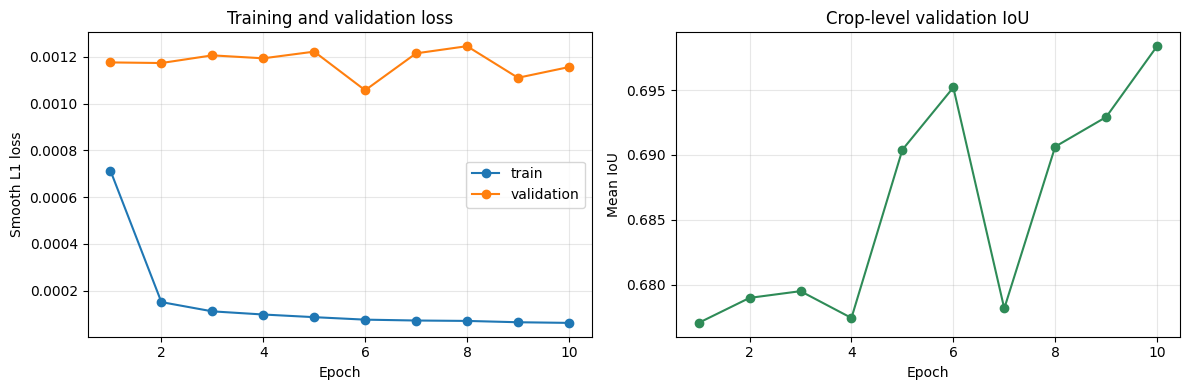

In [28]:
checkpoint_path = CHECKPOINT_ROOT / "best_tracking_regressor.pth"
if "history" not in globals() and checkpoint_path.is_file():
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    history = checkpoint.get("history", {})

if "history" in globals() and history:
    epochs = np.arange(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], marker="o", label="train")
    axes[0].plot(epochs, history["val_loss"], marker="o", label="validation")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Smooth L1 loss")
    axes[0].set_title("Training and validation loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(epochs, history["val_iou"], marker="o", color="seagreen")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Mean IoU")
    axes[1].set_title("Crop-level validation IoU")
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    fig.savefig(OUTPUT_ROOT / "training_curves.png", dpi=150, bbox_inches="tight")
    plt.show()


## 3.9 Visualize Crop-Level Validation Predictions

Visualize at least five validation crop predictions.

Draw:
- ground-truth box,
- predicted box.

This helps check whether the model learned meaningful localization.

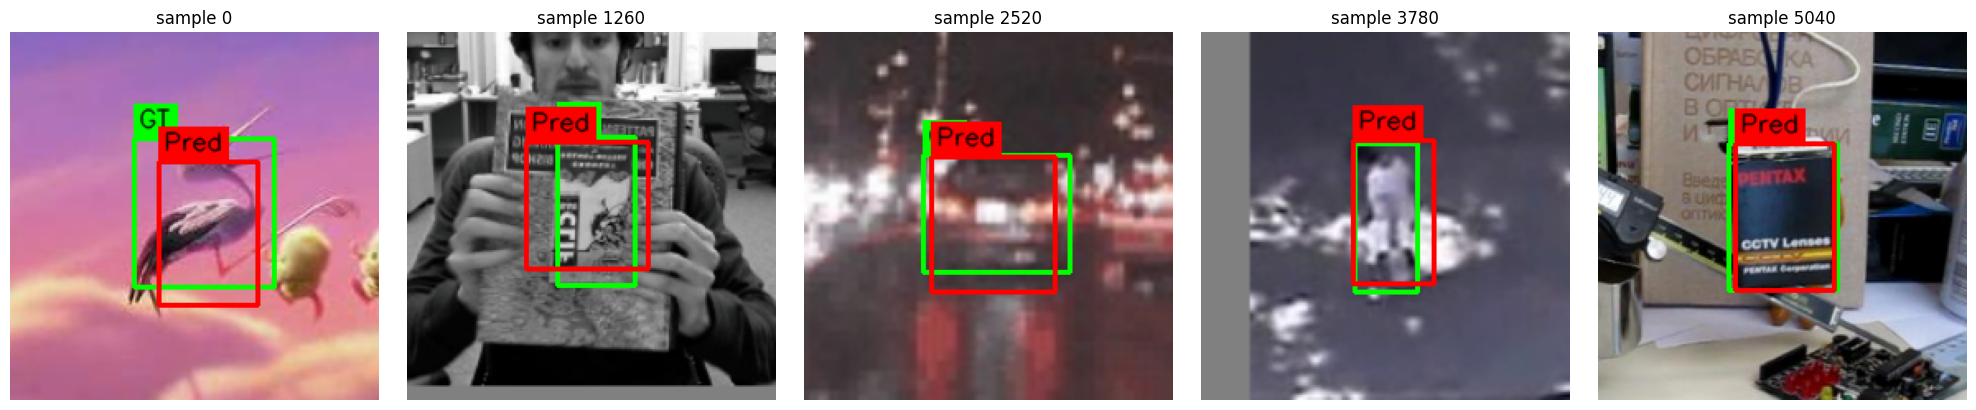

In [29]:
def denormalize_tensor_image(tensor_img: torch.Tensor) -> np.ndarray:
    """Convert a normalized tensor image back to a uint8 RGB image for visualization."""
    image = tensor_img.detach().cpu().clone()
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    image = image * std + mean
    image = image.clamp(0, 1).permute(1, 2, 0).numpy()
    return (image * 255).astype(np.uint8)


@torch.no_grad()
def visualize_validation_predictions(model, dataset, num_samples: int = 5):
    model.eval()
    num_samples = min(num_samples, len(dataset))
    if num_samples == 0:
        print("Validation dataset is empty.")
        return None

    indices = np.linspace(0, len(dataset) - 1, num_samples, dtype=int)
    fig, axes = plt.subplots(1, num_samples, figsize=(4 * num_samples, 4), squeeze=False)

    for ax, idx in zip(axes[0], indices):
        crop_tensor, target = dataset[int(idx)]
        prediction = model(crop_tensor.unsqueeze(0).to(DEVICE))[0].cpu()

        crop_rgb = denormalize_tensor_image(crop_tensor)
        target_pixels = target.numpy() * np.array([IMAGE_SIZE, IMAGE_SIZE, IMAGE_SIZE, IMAGE_SIZE], dtype=np.float32)
        pred_pixels = prediction.numpy() * np.array([IMAGE_SIZE, IMAGE_SIZE, IMAGE_SIZE, IMAGE_SIZE], dtype=np.float32)

        crop_rgb = draw_bbox(crop_rgb, target_pixels, color=(0, 255, 0), label="GT")
        crop_rgb = draw_bbox(crop_rgb, pred_pixels, color=(255, 0, 0), label="Pred")

        ax.imshow(crop_rgb)
        ax.axis("off")
        ax.set_title(f"sample {idx}")

    plt.tight_layout()
    fig.savefig(OUTPUT_ROOT / "validation_crop_predictions.png", dpi=150, bbox_inches="tight")
    plt.show()
    return fig


if "model" in globals() and "val_dataset" in globals():
    visualize_validation_predictions(model, val_dataset, num_samples=5)

# PART 4 — Single-Object Tracking on Validation and Test Sequences

After training the model, use it as a tracker.

For validation sequences:
- use the first line of `groundtruth_rect.txt` as initialization,
- predict all later frames,
- evaluate after tracking.

For test sequences:
- use `init_rect.txt` as initialization,
- predict all later frames,
- save CSV files,
- do not evaluate locally.

## 4.1 Evaluation-Time Preprocessing

Use the same preprocessing during tracking that you used during training.

Do not apply random augmentation during validation or test tracking.

In [30]:
eval_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

## 4.2 Predict a Box Inside One Crop

This helper runs the model on one search crop and returns a normalized crop-local bounding box.

In [31]:
@torch.no_grad()
def predict_bbox_in_crop(model, crop_rgb: np.ndarray, device: torch.device = DEVICE) -> np.ndarray:
    """Run the model on a crop and return normalized bbox prediction."""
    model.eval()
    crop_tensor = eval_transform(crop_rgb).unsqueeze(0).to(device)
    prediction = model(crop_tensor)[0].detach().cpu().numpy().astype(np.float32)
    return np.clip(prediction, 0.0, 1.0)

## 4.3 Tracking Loop

Implement the full single-object tracking loop.

The function should receive only:

```text
model
frame paths
initial bbox
```

It must not receive the full ground-truth array.

In [32]:
@torch.no_grad()
def track_sequence(
    model,
    frame_paths: List[Path],
    initial_bbox: np.ndarray,
    device: torch.device = DEVICE,
    scale: float = SEARCH_SCALE,
    image_size: int = IMAGE_SIZE,
) -> np.ndarray:
    """
    Track the target object through a sequence.

    Args:
        model: trained tracking model
        frame_paths: sorted list of frame paths
        initial_bbox: first-frame bbox, from GT or init_rect.txt
        device: torch device
        scale: search-region scale

    Returns:
        predictions: numpy array of shape (N, 4), full-frame bboxes

    Important:
        This function must not use ground-truth boxes after frame 1.
    """
    if len(frame_paths) == 0:
        return np.zeros((0, 4), dtype=np.float32)

    model.eval()
    predictions = np.zeros((len(frame_paths), 4), dtype=np.float32)

    first_image = read_image_rgb(frame_paths[0])
    predictions[0] = clip_bbox_to_image(np.asarray(initial_bbox, dtype=np.float32), first_image.shape)

    for frame_idx in range(1, len(frame_paths)):
        image = read_image_rgb(frame_paths[frame_idx])
        previous_bbox = predictions[frame_idx - 1]

        crop_rgb, crop_info = crop_search_region(
            image,
            previous_bbox,
            scale=scale,
            output_size=image_size,
        )
        predicted_crop_bbox = predict_bbox_in_crop(model, crop_rgb, device=device)
        predicted_frame_bbox = crop_to_frame_coordinates(predicted_crop_bbox, crop_info)
        if frame_idx > 1:
            prev_w, prev_h = previous_bbox[2], previous_bbox[3]
            curr_w, curr_h = predicted_frame_bbox[2], predicted_frame_bbox[3]
            smooth = 0.8
            predicted_frame_bbox[2] = smooth * prev_w + (1.0 - smooth) * curr_w
            predicted_frame_bbox[3] = smooth * prev_h + (1.0 - smooth) * curr_h

        predictions[frame_idx] = clip_bbox_to_image(predicted_frame_bbox, image.shape)
    return predictions

## 4.4 Save Prediction CSV Files

Save predictions in the required format.

The saved coordinates must be full-frame pixel coordinates.

In [33]:
def save_predictions_csv(predictions: np.ndarray, output_path: Path):
    """
    Save predictions in CSV format:

    frame,x,y,w,h
    1,...
    2,...

    Coordinates must be full-frame pixel coordinates, not normalized crop coordinates.
    """
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    with output_path.open("w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["frame", "x", "y", "w", "h"])
        for frame_number, bbox in enumerate(np.asarray(predictions, dtype=np.float32), start=1):
            writer.writerow([frame_number] + [f"{float(value):.6f}" for value in bbox])

## 4.5 Run Tracking on Validation Sequences

Use the first validation ground-truth box for initialization.

Save validation predictions under:

```text
outputs/validation/
```

In [34]:
def run_tracking_on_validation_sequences(
    model,
    data_root: Path,
    sequence_names: List[str],
    output_root: Path,
    device: torch.device = DEVICE,
    scale: float = SEARCH_SCALE,
) -> Dict[str, np.ndarray]:
    """Track validation sequences and save CSV prediction files."""
    predictions_by_sequence = {}
    validation_output_root = Path(output_root) / "validation"
    validation_output_root.mkdir(parents=True, exist_ok=True)

    for sequence_name in sequence_names:
        frame_paths, gt_bboxes = load_sequence_with_gt(Path(data_root) / sequence_name)
        predictions = track_sequence(
            model,
            frame_paths,
            gt_bboxes[0],
            device=device,
            scale=scale,
        )
        predictions_by_sequence[sequence_name] = predictions
        save_predictions_csv(predictions, validation_output_root / f"{sequence_name}_predictions.csv")

    return predictions_by_sequence

## 4.6 Run Tracking on Test Sequences

Use `init_rect.txt` for initialization.

Save test predictions under:

```text
outputs/test/
```

These files will be submitted for evaluation.

In [35]:
def run_tracking_on_test_sequences(
    model,
    data_root: Path,
    sequence_names: List[str],
    output_root: Path,
    device: torch.device = DEVICE,
    scale: float = SEARCH_SCALE,
) -> Dict[str, np.ndarray]:
    """Track test sequences and save CSV prediction files."""
    predictions_by_sequence = {}
    test_output_root = Path(output_root) / "test"
    test_output_root.mkdir(parents=True, exist_ok=True)

    for sequence_name in sequence_names:
        frame_paths, initial_bbox = load_test_sequence(Path(data_root) / sequence_name)
        predictions = track_sequence(
            model,
            frame_paths,
            initial_bbox,
            device=device,
            scale=scale,
        )
        predictions_by_sequence[sequence_name] = predictions
        save_predictions_csv(predictions, test_output_root / f"{sequence_name}_predictions.csv")

    return predictions_by_sequence

## 4.7 Execute Tracking

Run tracking on validation and test sequences.

Make sure the generated test CSV files are complete and correctly formatted.

In [36]:
if "model" not in globals():
    model = create_model()

checkpoint_path = CHECKPOINT_ROOT / "best_tracking_regressor.pth"
if checkpoint_path.is_file():
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"Loaded checkpoint from {checkpoint_path}")

if "val_sequences" not in globals():
    train_sequences, val_sequences, test_sequences = load_splits(SPLIT_ROOT)

validation_predictions = run_tracking_on_validation_sequences(
    model,
    DATA_ROOT,
    val_sequences,
    OUTPUT_ROOT,
    device=DEVICE,
    scale=SEARCH_SCALE,
)

test_predictions = run_tracking_on_test_sequences(
    model,
    DATA_ROOT,
    test_sequences,
    OUTPUT_ROOT,
    device=DEVICE,
    scale=SEARCH_SCALE,
)

Loaded checkpoint from checkpoint/best_tracking_regressor.pth


## 4.8 Visualize Test Tracking Results

The test ground-truth boxes are hidden, so only predicted boxes are drawn for test sequences.
For three representative test sequences, an early, middle, and late frame are shown.

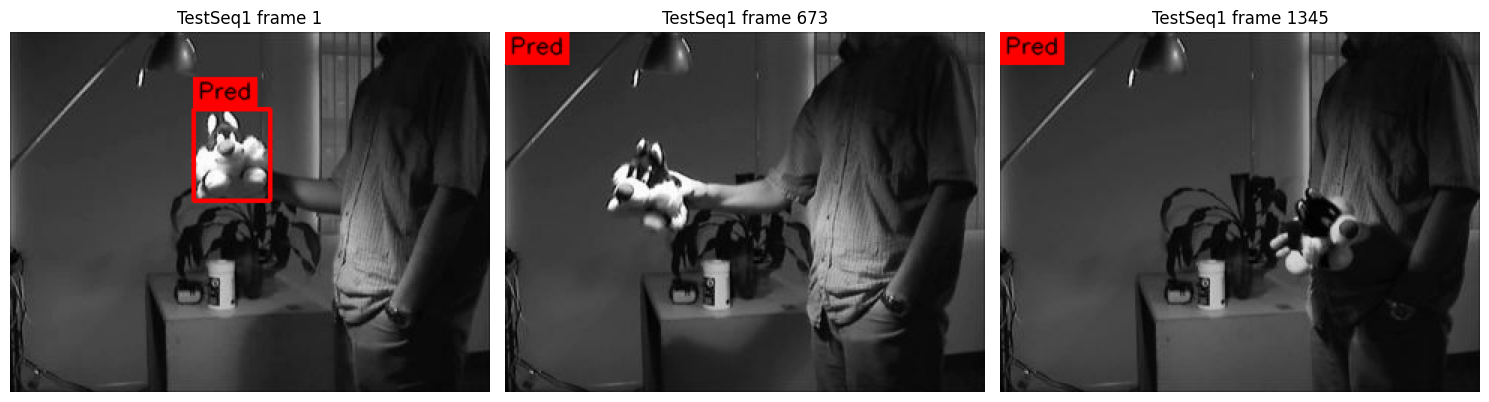

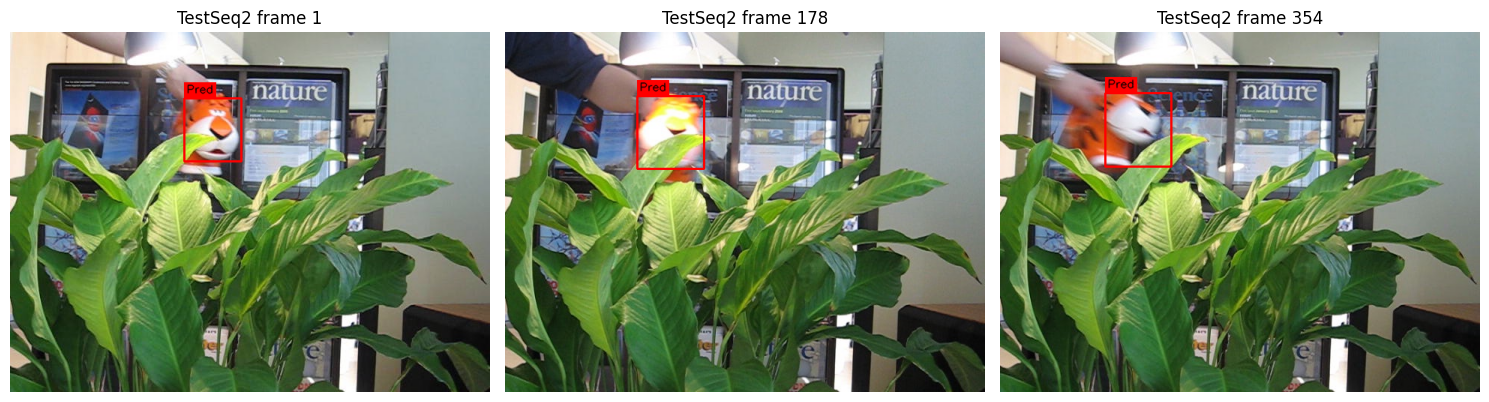

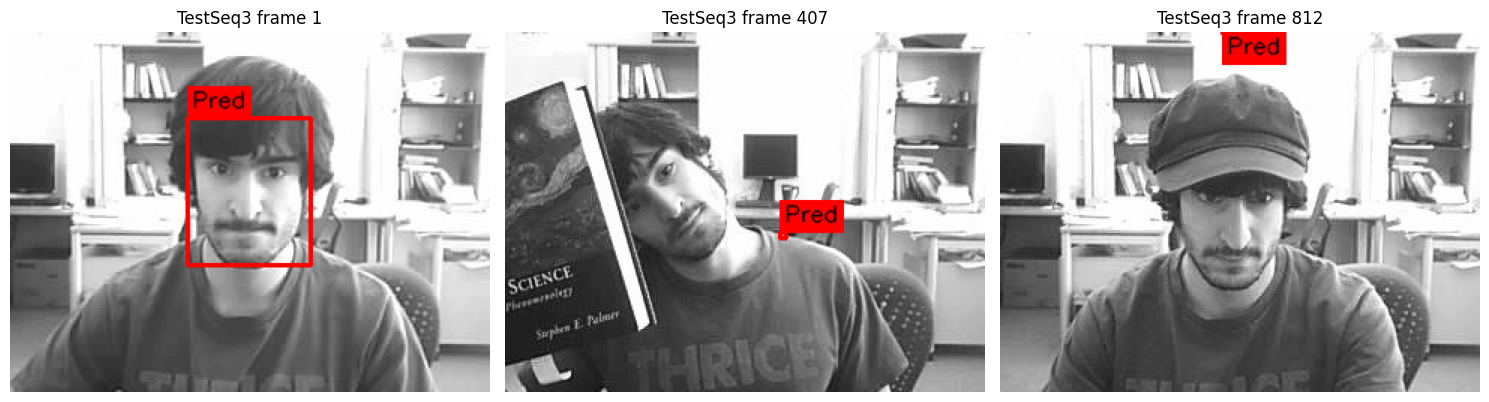

In [37]:
def visualize_test_tracking_result(
    sequence_name: str,
    predictions: np.ndarray,
    data_root: Path,
    frame_indices: Optional[List[int]] = None,
    output_tag: str = "tracking_preview",
):
    """Visualize test tracking predictions. Test GT is hidden, so only predictions are drawn."""
    frame_paths, _ = load_test_sequence(Path(data_root) / sequence_name)
    predictions = np.asarray(predictions, dtype=np.float32)

    if frame_indices is None:
        frame_indices = sorted(set([0, len(frame_paths) // 2, len(frame_paths) - 1]))

    fig, axes = plt.subplots(1, len(frame_indices), figsize=(5 * len(frame_indices), 4), squeeze=False)

    for ax, frame_idx in zip(axes[0], frame_indices):
        image = read_image_rgb(frame_paths[frame_idx])
        image = draw_bbox(image, predictions[frame_idx], color=(255, 0, 0), label="Pred")
        ax.imshow(image)
        ax.axis("off")
        ax.set_title(f"{sequence_name} frame {frame_idx + 1}")

    plt.tight_layout()
    output_path = OUTPUT_ROOT / "test" / f"{sequence_name}_{output_tag}.png"
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()
    return fig


if "test_predictions" in globals():
    representative_test_sequences = test_sequences[:3]

    for sequence_name in representative_test_sequences:
        if sequence_name in test_predictions:
            visualize_test_tracking_result(
                sequence_name,
                test_predictions[sequence_name],
                DATA_ROOT,
                output_tag="tracking_preview",)

# Required Test Output Format

For each test sequence, save one CSV file:

```text
outputs/test/<sequence_name>_predictions.csv
```

Each CSV file must contain:

```text
frame,x,y,w,h
```

Rules:

1. Number of rows must equal the number of frames.
2. Frame numbering must start from 1.
3. The first-frame prediction should be the initialization box from `init_rect.txt`.
4. Coordinates must be full-frame pixel coordinates.
5. Do not save normalized crop coordinates.
6. Bounding boxes must be in `(x, y, width, height)` format.

# PART 5 — Validation Evaluation and Analysis

Evaluate your tracker on validation sequences using the provided validation ground truth.

Do not evaluate test sequences. Test ground truth is hidden and will be evaluated by the instructors.

Required validation metrics:

1. Mean IoU  
2. Success Rate @ IoU ≥ 0.5  
3. Average Center Error  
4. Failure Count, where failure means IoU < 0.1

## 5.1 Metric Functions

Implement IoU, center error, and sequence-level evaluation.

In [38]:
def compute_iou(box_a: np.ndarray, box_b: np.ndarray) -> float:
    """Compute intersection-over-union between two boxes in (x, y, w, h) format."""
    return compute_iou_np(box_a, box_b)


def compute_center_error(box_a: np.ndarray, box_b: np.ndarray) -> float:
    """Compute Euclidean distance between the centers of two boxes."""
    ax, ay = bbox_center(box_a)
    bx, by = bbox_center(box_b)
    return float(math.sqrt((ax - bx) ** 2 + (ay - by) ** 2))


def evaluate_sequence(
    predictions: np.ndarray,
    ground_truth: np.ndarray,
    success_iou_threshold: float = 0.5,
    failure_iou_threshold: float = 0.1,
) -> Dict[str, float]:
    """
    Evaluate one validation tracking sequence.

    Returns:
        metrics dictionary with:
        - mean_iou
        - success_rate_0.5
        - avg_center_error
        - failure_count
        - num_frames
    """
    predictions = np.asarray(predictions, dtype=np.float32)
    ground_truth = np.asarray(ground_truth, dtype=np.float32)

    if len(predictions) != len(ground_truth):
        raise ValueError(
            f"Prediction/GT length mismatch: {len(predictions)} predictions, "
            f"{len(ground_truth)} GT boxes"
        )

    ious = np.array([compute_iou(pred, gt) for pred, gt in zip(predictions, ground_truth)], dtype=np.float32)
    center_errors = np.array(
        [compute_center_error(pred, gt) for pred, gt in zip(predictions, ground_truth)],
        dtype=np.float32,
    )

    return {
        "mean_iou": float(np.mean(ious)) if len(ious) else 0.0,
        "success_rate_0.5": float(np.mean(ious >= success_iou_threshold)) if len(ious) else 0.0,
        "avg_center_error": float(np.mean(center_errors)) if len(center_errors) else 0.0,
        "failure_count": int(np.sum(ious < failure_iou_threshold)),
        "num_frames": int(len(predictions)),
    }

## 5.2 Evaluate All Validation Sequences

Create a result table with one row per validation sequence and one final average row.

In [39]:
def evaluate_validation_sequences(
    predictions_by_sequence: Dict[str, np.ndarray],
    data_root: Path,
) -> pd.DataFrame:
    """Evaluate all validation sequences and return a result table."""
    rows = []
    for sequence_name, predictions in predictions_by_sequence.items():
        _, gt_bboxes = load_sequence_with_gt(Path(data_root) / sequence_name)
        metrics = evaluate_sequence(predictions, gt_bboxes)
        rows.append({"Sequence": sequence_name, **metrics})

    results_df = pd.DataFrame(rows)
    if not results_df.empty:
        average_row = {"Sequence": "Average"}
        for column in ["mean_iou", "success_rate_0.5", "avg_center_error", "failure_count", "num_frames"]:
            average_row[column] = float(results_df[column].mean())
        results_df = pd.concat([results_df, pd.DataFrame([average_row])], ignore_index=True)

    results_df.to_csv(OUTPUT_ROOT / "validation_metrics.csv", index=False)
    return results_df


if "validation_predictions" in globals():
    validation_results = evaluate_validation_sequences(validation_predictions, DATA_ROOT)
    display(validation_results)

,Sequence,mean_iou,success_rate_0.5,avg_center_error,failure_count,num_frames
0,Bird2,0.209453,0.020202,62.331646,39.000000,99.000000
1,Fish,0.064209,0.042017,126.758324,403.000000,476.000000
2,Human4,0.091554,0.056972,121.969147,519.000000,667.000000
3,ClifBar,0.015032,0.008475,124.345253,458.000000,472.000000
4,Bolt,0.322135,0.314286,31.925810,134.000000,350.000000
5,MountainBike,0.201383,0.013158,19.321589,31.000000,228.000000
6,CarDark,0.136649,0.040712,57.455452,236.000000,393.000000
7,Man,0.813182,1.000000,2.067140,0.000000,134.000000
8,Basketball,0.041067,0.023448,191.540390,632.000000,725.000000
9,Crowds,0.064590,0.074928,368.538239,304.000000,347.000000


## 5.3 Visualize Validation Tracking Results

Visualize tracking results for at least three validation sequences.

For each selected sequence, show:
- an early frame,
- a middle frame,
- a late frame.

Draw both the ground-truth and predicted bounding boxes.

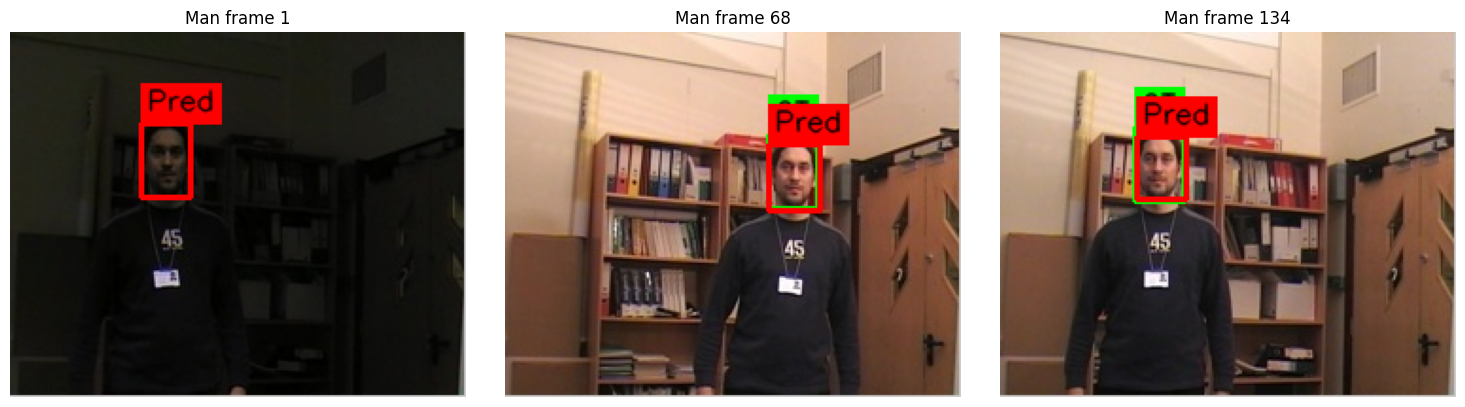

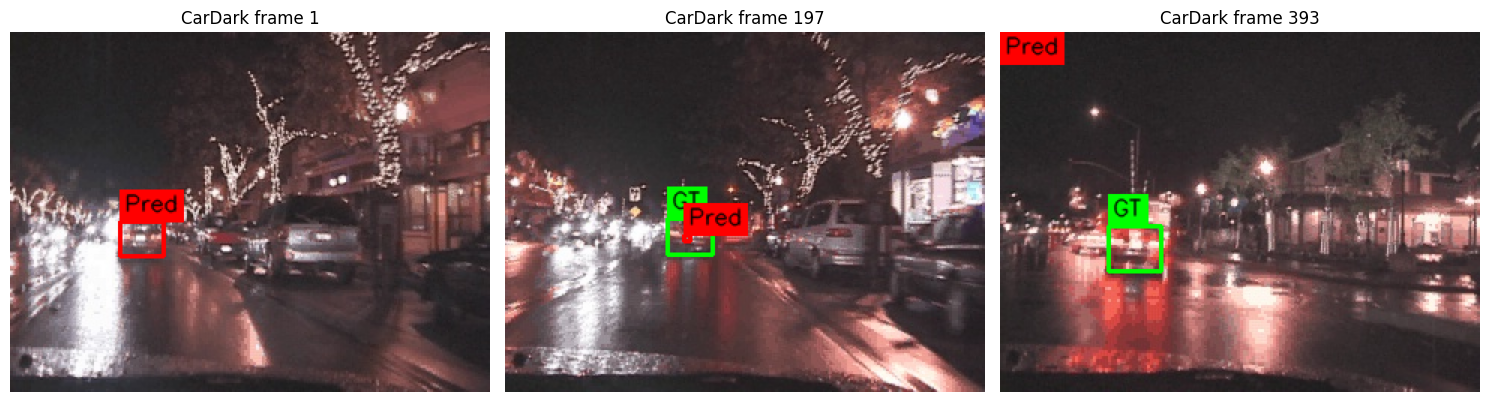

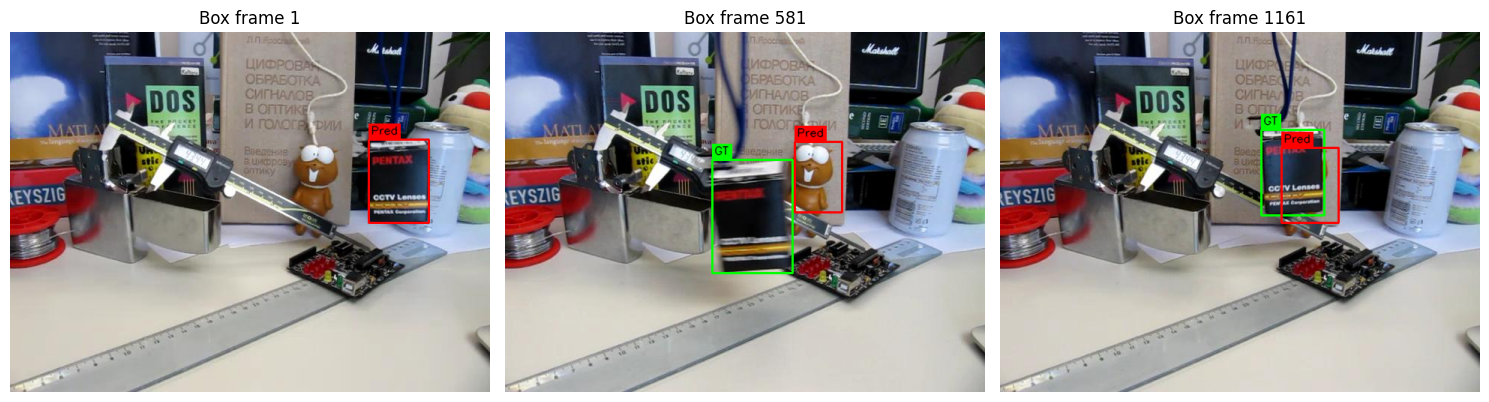

In [40]:
def visualize_validation_tracking_result(
    sequence_name: str,
    predictions: np.ndarray,
    data_root: Path,
    frame_indices: Optional[List[int]] = None,
    output_tag: str = "tracking_preview",
):
    """Visualize tracking predictions and ground truth for selected validation frames."""
    frame_paths, gt_bboxes = load_sequence_with_gt(Path(data_root) / sequence_name)
    predictions = np.asarray(predictions, dtype=np.float32)

    if frame_indices is None:
        frame_indices = sorted(set([0, len(frame_paths) // 2, len(frame_paths) - 1]))

    fig, axes = plt.subplots(1, len(frame_indices), figsize=(5 * len(frame_indices), 4), squeeze=False)
    for ax, frame_idx in zip(axes[0], frame_indices):
        image = read_image_rgb(frame_paths[frame_idx])
        image = draw_bbox(image, gt_bboxes[frame_idx], color=(0, 255, 0), label="GT")
        image = draw_bbox(image, predictions[frame_idx], color=(255, 0, 0), label="Pred")
        ax.imshow(image)
        ax.axis("off")
        ax.set_title(f"{sequence_name} frame {frame_idx + 1}")

    plt.tight_layout()
    output_path = OUTPUT_ROOT / "validation" / f"{sequence_name}_{output_tag}.png"
    output_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(output_path, dpi=150, bbox_inches="tight")
    plt.show()
    return fig


if "validation_predictions" in globals():
    representative_sequences = ["Man", "CarDark", "Box"]
    for sequence_name in representative_sequences:
        if sequence_name in validation_predictions:
            visualize_validation_tracking_result(
                sequence_name,
                validation_predictions[sequence_name],
                DATA_ROOT,
                output_tag="tracking_preview",
            )

## 5.4 Failure-Case Analysis

Find frames where the tracker performs poorly.

At minimum, show:
- three successful frames,
- three failure cases.

For each failure case, explain what went wrong.

Successful validation frames:


,sequence,frame,iou,center_error
1938,Bolt,230,0.883322,2.833732
2788,Man,112,0.866679,0.973142
2790,Man,114,0.865384,1.238160


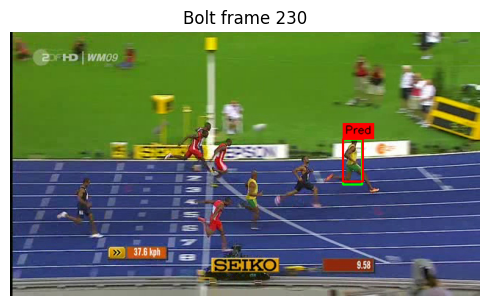

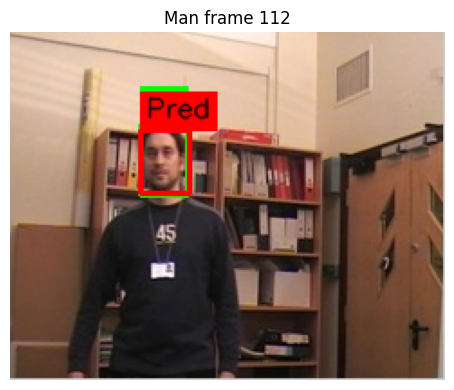

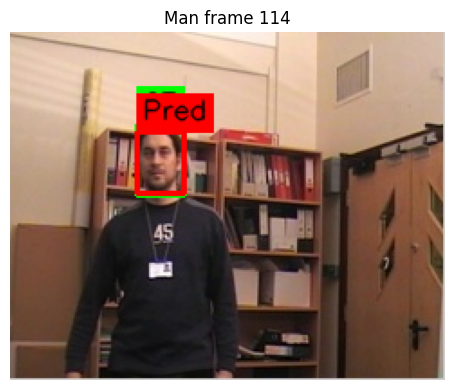

Failure validation frames:


,sequence,frame,iou,center_error
2573,CarDark,289,0.0,114.328762
2593,CarDark,309,0.0,150.250060
2578,CarDark,294,0.0,123.069440


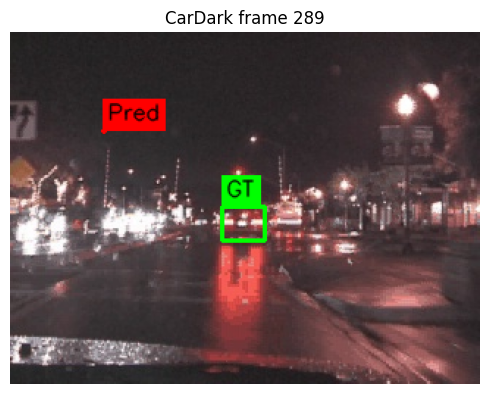

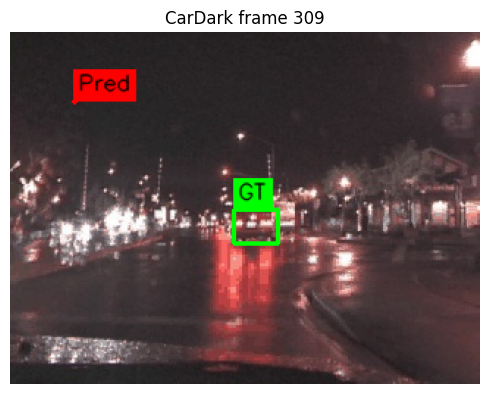

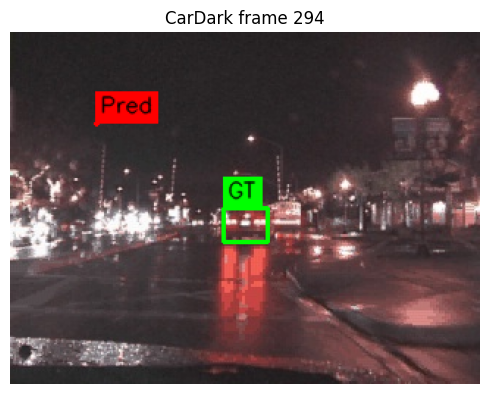

In [41]:
def collect_validation_frame_quality(
    predictions_by_sequence: Dict[str, np.ndarray],
    data_root: Path,
) -> pd.DataFrame:
    """Collect per-frame IoU and center error values for validation predictions."""
    rows = []
    for sequence_name, predictions in predictions_by_sequence.items():
        _, gt_bboxes = load_sequence_with_gt(Path(data_root) / sequence_name)
        for frame_idx, (pred, gt) in enumerate(zip(predictions, gt_bboxes)):
            if frame_idx == 0:
                continue
            rows.append({
                "sequence": sequence_name,
                "frame_index": frame_idx,
                "frame": frame_idx + 1,
                "iou": compute_iou_np(pred, gt),
                "center_error": compute_center_error(pred, gt),
            })
    return pd.DataFrame(rows)


def find_worst_validation_frames(
    sequence_name: str,
    predictions: np.ndarray,
    data_root: Path,
    k: int = 3,
) -> List[int]:
    """Return indices of the k validation frames with the lowest IoU."""
    _, gt_bboxes = load_sequence_with_gt(Path(data_root) / sequence_name)
    ious = []
    for i in range(1, len(predictions)):
        iou = compute_iou_np(predictions[i], gt_bboxes[i])
        ious.append((i, iou))

    ious.sort(key=lambda x: x[1])
    return [idx for idx, _ in ious[:k]]


if "validation_predictions" in globals():
    frame_quality = collect_validation_frame_quality(validation_predictions, DATA_ROOT)
    frame_quality.to_csv(OUTPUT_ROOT / "validation_frame_quality.csv", index=False)

    successful_cases = frame_quality.sort_values("iou", ascending=False).head(3)
    failure_cases = frame_quality.sort_values("iou", ascending=True).head(3)

    print("Successful validation frames:")
    display(successful_cases[["sequence", "frame", "iou", "center_error"]])
    for _, row in successful_cases.iterrows():
        seq_name = row["sequence"]
        frame_idx = int(row["frame_index"])
        visualize_validation_tracking_result(
            seq_name,
            validation_predictions[seq_name],
            DATA_ROOT,
            frame_indices=[frame_idx],
            output_tag=f"success_frame_{frame_idx + 1}",
        )

    print("Failure validation frames:")
    display(failure_cases[["sequence", "frame", "iou", "center_error"]])
    for _, row in failure_cases.iterrows():
        seq_name = row["sequence"]
        frame_idx = int(row["frame_index"])
        visualize_validation_tracking_result(
            seq_name,
            validation_predictions[seq_name],
            DATA_ROOT,
            frame_indices=[frame_idx],
            output_tag=f"failure_frame_{frame_idx + 1}",
        )


# Optional — Tracking Video Export

You may create MP4 visualizations of your validation tracking results.

This is optional, but it can help you inspect long sequences more easily.

In [42]:
def create_validation_tracking_video(
    sequence_name: str,
    predictions: np.ndarray,
    data_root: Path,
    output_path: Path,
    fps: int = 20,
):
    """Create an MP4 video showing ground-truth and predicted boxes for a validation sequence."""
    frame_paths, gt_bboxes = load_sequence_with_gt(Path(data_root) / sequence_name)
    predictions = np.asarray(predictions, dtype=np.float32)

    if len(predictions) != len(frame_paths):
        raise ValueError(
            f"Prediction/frame length mismatch for {sequence_name}: "
            f"{len(predictions)} predictions vs {len(frame_paths)} frames"
        )

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    first_image = read_image_rgb(frame_paths[0])
    height, width = first_image.shape[:2]

    writer = cv2.VideoWriter(
        str(output_path),
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height),
    )

    if not writer.isOpened():
        raise RuntimeError(f"Could not create video writer for: {output_path}")

    for frame_idx, frame_path in enumerate(frame_paths):
        image_rgb = read_image_rgb(frame_path)
        image_rgb = draw_bbox(image_rgb, gt_bboxes[frame_idx], color=(0, 255, 0), label="GT")
        image_rgb = draw_bbox(image_rgb, predictions[frame_idx], color=(255, 0, 0), label="Pred")

        image_bgr = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)
        writer.write(image_bgr)

    writer.release()
    print(f"Saved video to {output_path}")

# Discussion Questions

Write your discussions about the performance, best/failure cases, metrics, etc.

Use your validation metrics, visualizations, and failure cases as evidence.

## Discussion Notes

In this assignment, a CNN-based closed-loop single-object tracker was implemented using a ResNet18 bounding-box regressor. The model receives a local search-region crop resized to 224 x 224 and predicts a normalized crop-local bounding box in `(x, y, width, height)` format. This prediction is converted back to full-frame coordinates and used as the search center for the next frame.

The final model uses ImageNet-pretrained ResNet18, Smooth L1 loss, Adam optimizer, batch size 32, learning rate `1e-4`, 10 epochs, and a search-region scale of `2.5 x max(previous_width, previous_height)`. The best model is saved as `checkpoint/best_tracking_regressor.pth`. To reduce tracking drift, random translation noise was added to the previous bounding box during training. During tracking, EMA-style width/height smoothing with factor 0.8 was used to reduce sudden box-size changes. A 50% horizontal flip augmentation was also used during training.

The crop-level validation results show that the CNN regressor learns the local search-region localization task. The best saved model reaches a crop-level validation IoU of about **0.70** with validation Smooth L1 loss around **0.0011**. This means that when the search crop is generated using the previous ground-truth box, the model can usually localize the object inside the crop. Therefore, the model does not simply output constant boxes.

Sequence-level tracking is harder because the tracker uses its own previous prediction instead of the ground-truth box. An inaccurate prediction shifts the next crop, and repeated errors can cause the target to become off-center, partially visible, or outside the search region. Since this implementation does not include a recovery mechanism, these errors can accumulate over time.

Across the 11 validation sequences, the average mean IoU is **0.1858**, the average success rate at IoU >= 0.5 is **0.1474**, the average center error is **109.52 pixels**, and the average failure count is **331.55 frames**. These results show that the model performs better in stable local crops than in long closed-loop tracking.

**Success cases.** The clearest success case is **Man**, with **0.8132 mean IoU**, **1.0000 success rate**, **2.07 pixels** average center error, and **0 failures**. The target appearance and scale remain stable, so the previous prediction remains a reliable search center. **Bolt** is another relatively strong case, with **0.3221 mean IoU**, **0.3143 success rate**, and **31.93 pixels** average center error. The tracker follows the target better than in many other sequences, although some frames still fail because the predicted box does not always match the object scale. **MountainBike** is a partial success: it reaches **0.2014 mean IoU** with **19.32 pixels** average center error. This suggests that the tracker often stays near the object center, although the predicted box size is not accurate enough for high IoU in many frames.

**Failure cases.** **Box** is one of the hardest cases, with **891 failures** over **1161 frames**. Once the prediction drifts, later crops are centered on the wrong region and the tracker cannot recover. **Basketball** also fails strongly, with **0.0411 mean IoU**, **191.54 pixels** average center error, and **632 failures**, mainly due to fast motion, clutter, and drift. **Crowds** has **368.54 pixels** average center error and **304 failures** because the target is difficult to distinguish from nearby people.

The generated test CSV files follow the required hidden-test submission format. Each file is saved under `outputs/test/<sequence_name>_predictions.csv`, uses the header `frame,x,y,w,h`, contains one row per frame, starts frame numbering from 1, copies the first-frame initialization box from `init_rect.txt`, and stores full-frame pixel coordinates in `(x, y, width, height)` format.

Overall, the tracker demonstrates the basic CNN-based bounding-box regression approach for single-object tracking. The main remaining weakness is tracking drift, especially under fast motion, scale change, ambiguous background, and occlusion. Future improvements could include stronger noisy-box augmentation, validation-based search-scale tuning, center smoothing, and a simple recovery mechanism when the tracker drifts away from the target.

# Final Implementation Summary

Before submission, summarize your final settings here.

## Final Settings

**Backbone architecture:** ResNet18 with the ImageNet classification head replaced by a 4-value bounding-box regression layer  
**Pretrained weights used?** Yes, `torchvision.models.ResNet18_Weights.DEFAULT` is used for ImageNet pretrained weights  
**Input size:** 224 x 224 RGB search crop  
**Search-region scale:** 2.5 x `max(previous_width, previous_height)`  
**Batch size:** 32  
**Learning rate:** 1e-4  
**Number of epochs:** 10  
**Optimizer:** Adam  
**Loss function:** Smooth L1 loss  
**Training augmentation:** random translation noise on the previous bbox, plus 50% horizontal flip  
**Tracking smoothing:** EMA-style smoothing on predicted width/height with factor 0.8  
**Best checkpoint:** `checkpoint/best_tracking_regressor.pth`  
**Sequence tracking strategy:** CNN-only closed-loop tracker. Each frame is cropped around the previous predicted box, the trained ResNet18 regressor predicts a normalized crop-local box, and that box is converted back to full-frame coordinates for the next step.  



# Submission Checklist

Before submitting, make sure that:

- [x] The notebook is organized to run from beginning to end without manual intervention.
- [x] The code uses only the provided train/validation/test splits.
- [x] Validation/test tracking use only the first-frame initialization box.
- [x] The validation result table is included and saved as `outputs/validation_metrics.csv`.
- [x] Required visualizations and analysis figures are saved under `outputs/`.
- [x] Test prediction CSV files are saved under `outputs/test/`.
- [x] CSV files contain full-frame pixel coordinates, not normalized crop coordinates.
- [x] The trained model weights are saved under `checkpoint/`.